<a href="https://colab.research.google.com/github/SeekerKids/Portofolio/blob/main/Case_Study_2_Customer_Churn_menggunakan_RandomForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Case Study 2: Customer Churn menggunakan RandomForest**


# Input Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tabulate import tabulate
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

file_path = '/content/drive/MyDrive/SDI/Case Study 2: Customer Churn menggunakan Random Forest/Case 2 - Customer Churn.csv'
df = pd.read_csv(file_path)

In [ ]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


# Preprocessing

In [ ]:
from tabulate import tabulate

# Data Information using tabulate
data_info = []
for col in df.columns:
    data_info.append([
        col,
        df[col].isna().sum(),
        df[col].isnull().sum(),
        df[col].dtype,
        df[col].nunique(),
        df[col].unique()[:5]  # Display the first 5 unique values
    ])


print(tabulate(data_info, headers=["Column Name", "Missing Values", "Data Type", "Unique Values", "Sample Values"], tablefmt="grid"))
print(f"Number of rows: {len(df)}")

+------------------+---------------+------------------+-------------+-----------------+--------------------------------------------------------------------+
|                  |   Column Name |   Missing Values | Data Type   |   Unique Values | Sample Values                                                      |
+==================+===============+==================+=============+=================+====================================================================+
| customerID       |             0 |                0 | object      |            7043 | ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' '7795-CFOCW' '9237-HQITU'] |
+------------------+---------------+------------------+-------------+-----------------+--------------------------------------------------------------------+
| gender           |             0 |                0 | object      |               2 | ['Female' 'Male']                                                  |
+------------------+---------------+------------------+---

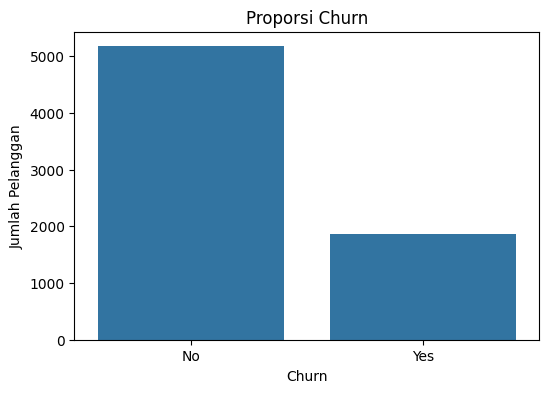

Proporsi Churn:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


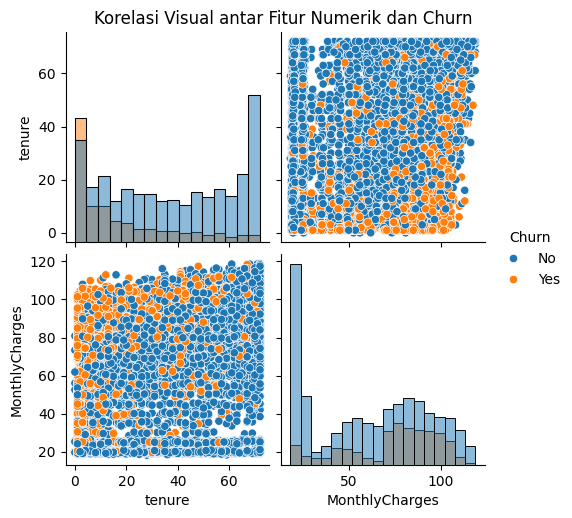

In [ ]:
#  Distribusi Churn
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df)
plt.title('Proporsi Churn')
plt.xlabel('Churn')
plt.ylabel('Jumlah Pelanggan')
plt.show()

#  Tampilkan proporsi Churn
print("Proporsi Churn:")
print(df['Churn'].value_counts(normalize=True).round(3))

#  Korelasi Numerik dengan Pairplot
num_cols = ['tenure', 'MonthlyCharges']
sns.pairplot(df[num_cols + ['Churn']], hue='Churn', diag_kind='hist')
plt.suptitle('Korelasi Visual antar Fitur Numerik dan Churn', y=1.02)
plt.show()

In [ ]:
# Ubah tipe data menjadi numerik dan saat perubahan tipe data ditemukan 11 missing value
# Menghilangkan missing value menggunakan dropna
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(inplace=True)

# Menghapus kolom customerID karena tidak mengandung informasi berguna untuk prediksi — malah bisa menyesatkan model
df.drop('customerID', axis=1, inplace=True)

In [ ]:
# kolom kategorikal karena Algoritma Random Forest butuh input numerik
# Ubah nilai kategorikal jadi angka
#  “No” “Yes” = 0 1
#  “Female” “Male” = 0 1
#  “No phone service”  “No”  “Yes” = 1 0 2
#  “DSL”  “Fiber Optic”  “No” = 0 1 2
#  “No”  “Yes” “X” = 0 2 1
#  “MtM” “One year” “Two year” = 0 1 2
#  “EC” “MC” “BT” “CC” = 2 3 0 1

for col in df.select_dtypes(include='object').columns:
    if col != 'Churn':
        df[col] = LabelEncoder().fit_transform(df[col])

# Ubah nilai target Churn jadi numerik
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

In [ ]:
from tabulate import tabulate

# Data Information using tabulate
data_info = []
for col in df.columns:
    data_info.append([
        col,
        df[col].isna().sum(),
        df[col].isnull().sum(),
        df[col].dtype,
        df[col].nunique(),
        df[col].unique()[:5]  # Display the first 5 unique values
    ])


print(tabulate(data_info, headers=["Column Name", "Missing Values", "Data Type", "Unique Values", "Sample Values"], tablefmt="grid"))
print(f"Number of rows: {len(df)}")

+------------------+---------------+------------------+-------------+-----------------+-------------------------------------------+
|                  |   Column Name |   Missing Values | Data Type   |   Unique Values | Sample Values                             |
+==================+===============+==================+=============+=================+===========================================+
| gender           |             0 |                0 | int64       |               2 | [0 1]                                     |
+------------------+---------------+------------------+-------------+-----------------+-------------------------------------------+
| SeniorCitizen    |             0 |                0 | int64       |               2 | [0 1]                                     |
+------------------+---------------+------------------+-------------+-----------------+-------------------------------------------+
| Partner          |             0 |                0 | int64       |       

# Split data

In [ ]:
X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Normalisasi

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Bangun Model

| **Hyperparameter**     | **Tipe**                        | **Fungsi**                                                                                                                                  |
|------------------------|----------------------------------|---------------------------------------------------------------------------------------------------------------------------------------------|
| `n_estimators`         | int                              | Jumlah pohon dalam hutan. Semakin banyak, model makin stabil, tapi waktu komputasi bertambah.                                               |
| `max_depth`            | int / None                       | Kedalaman maksimum tiap pohon. Bisa membatasi overfitting.                                                                                  |
| `min_samples_split`    | int / float                      | Minimum jumlah sampel untuk membagi node. Nilai besar = pohon tidak terlalu dalam (mengurangi overfitting).                                |
| `min_samples_leaf`     | int / float                      | Minimum jumlah sampel di daun. Nilai lebih besar membuat model lebih general dan stabil.                                                    |
| `max_features`         | int / float / {"sqrt", "log2"}   | Jumlah fitur yang dipertimbangkan saat split. `"sqrt"` (default di klasifikasi) sering bekerja baik.                                       |
| `bootstrap`            | bool                             | Apakah menggunakan bootstrap sampling (default: `True`). Jika `False`, gunakan seluruh data tiap pohon.                                    |
| `criterion`            | str                              | Fungsi untuk mengukur kualitas split: `"gini"` atau `"entropy"` (mutual information). Gini biasanya lebih cepat.                           |
| `class_weight`         | dict / "balanced"                | Menangani data tidak seimbang (imbalanced). `"balanced"` akan memberi bobot lebih pada kelas minoritas.                                   |
| `random_state`         | int                              | Seed untuk hasil yang bisa direproduksi (reproducible).                                                                                     |
| `max_leaf_nodes`       | int / None                       | Batasi jumlah node daun maksimum. Mengontrol kompleksitas pohon.                                                                            |
| `n_jobs`               | int                              | Jumlah core CPU yang digunakan. `-1` berarti gunakan semua core → lebih cepat saat Grid Search atau pelatihan besar.                        |
| `oob_score`            | bool                             | Jika `True`, gunakan *out-of-bag* samples untuk validasi (seperti cross-validation internal, tanpa pisah data).                            |


In [ ]:
# Tuning hyperparameter
param_grid = {
    'n_estimators': [200,250,300],
    'max_depth': [1,5,10,20],
    'min_samples_split': [2, 5,10,15],
    'min_samples_leaf': [1, 2]
}

rf = RandomForestClassifier(random_state=42)

grid_search = GridSearchCV(estimator=rf,
                           param_grid=param_grid,
                           cv=5,
                           scoring='accuracy',
                           n_jobs=-1,
                           verbose=2)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 96 candidates, totalling 480 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [1, 5, 10, 20],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5, 10, 15],
                         'n_estimators': [200, 250, 300]},
             scoring='accuracy', verbose=2)

In [ ]:
# Konversi hasil grid search ke DataFrame
results_df = pd.DataFrame(grid_search.cv_results_)

# Ekstrak parameter dari dictionary ke kolom baru
results_df['n_estimators'] = results_df['params'].apply(lambda x: x['n_estimators'])
results_df['max_depth'] = results_df['params'].apply(lambda x: x['max_depth'])
results_df['min_samples_split'] = results_df['params'].apply(lambda x: x['min_samples_split'])
results_df['min_samples_leaf'] = results_df['params'].apply(lambda x: x['min_samples_leaf'])

# Pilih kolom yang ingin ditampilkan
results_df = results_df[[
    'n_estimators',
    'max_depth',
    'min_samples_split',
    'min_samples_leaf',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]]

# Urutkan berdasarkan performa terbaik
results_df = results_df.sort_values(by='rank_test_score')

# Tampilkan semua hasil
#pd.set_option('display.max_rows', None)  # Agar semua baris ditampilkan
print(results_df)


    n_estimators  max_depth  min_samples_split  min_samples_leaf  \
57           200         10                 15                 1   
59           300         10                 15                 1   
69           200         10                 15                 2   
58           250         10                 15                 1   
71           300         10                 15                 2   
..           ...        ...                ...               ...   
3            200          1                  5                 1   
4            250          1                  5                 1   
5            300          1                  5                 1   
6            200          1                 10                 1   
7            250          1                 10                 1   

    mean_test_score  std_test_score  rank_test_score  
57         0.804622        0.013249                1  
59         0.804444        0.013725                2  
69         0.80373

# Evaluasi

In [ ]:
# Evaluasi Model Terbaik
best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Score:", grid_search.best_score_)

print("\nTest Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 15, 'n_estimators': 200}
Best Cross-Validation Score: 0.8046222222222221

Test Accuracy: 0.7910447761194029
Confusion Matrix:
 [[929 104]
 [190 184]]
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.64      0.49      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



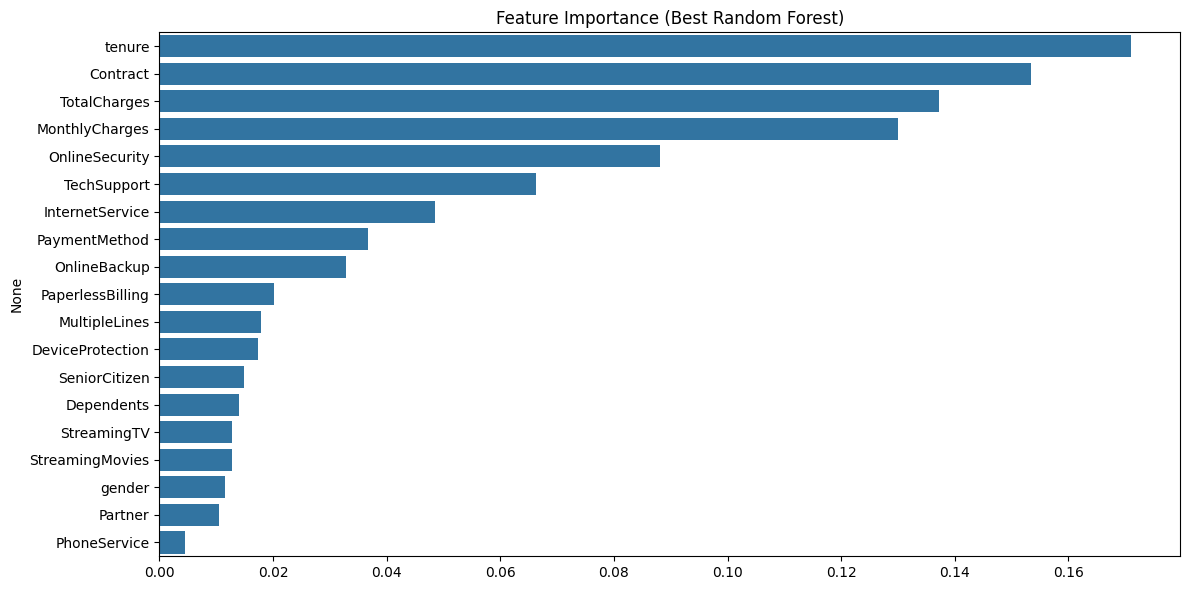

In [ ]:
# Visualisasi Feature Importance
importances = best_rf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 6))
sns.barplot(x=importances[indices], y=X.columns[indices])
plt.title('Feature Importance (Best Random Forest)')
plt.tight_layout()
plt.show()

## 🔍 Feature Importance - Random Forest

Berikut adalah hasil peringkat fitur berdasarkan **kontribusinya terhadap prediksi Churn** menggunakan model **Random Forest terbaik**:

### 📊 Top 5 Fitur Paling Penting

| **Fitur**         | **Penjelasan**                                                                 |
|-------------------|---------------------------------------------------------------------------------|
| `tenure`          | Lama pelanggan berlangganan. Semakin lama biasanya cenderung loyal.             |
| `Contract`        | Jenis kontrak (bulanan, 1 tahun, 2 tahun). Kontrak jangka panjang = lebih loyal.|
| `TotalCharges`    | Total biaya yang telah dibayarkan. Pelanggan dengan biaya tinggi bisa lebih terikat. |
| `MonthlyCharges`  | Biaya langganan bulanan. Biaya tinggi bisa memicu churn jika dianggap tidak sepadan. |
| `OnlineSecurity`  | Pelanggan yang memakai fitur keamanan biasanya lebih puas dan bertahan.         |

---

### 🧾 **Insight dari Hasil Ini**

- Pelanggan yang **sudah lama berlangganan** (`tenure`) cenderung tidak churn.
- **Jenis kontrak** sangat penting. Kontrak jangka pendek seperti *month-to-month* lebih rentan churn.
- **Fitur keamanan dan dukungan teknis** meningkatkan loyalitas pelanggan.
- Fitur seperti `gender`, `Partner`, `PhoneService` kurang berpengaruh dalam prediksi churn.

---

### 🎯 **Rekomendasi Strategi Bisnis**

- Dorong pelanggan *month-to-month* untuk upgrade ke kontrak tahunan.
- Buat program loyalitas berbasis `tenure`.
- Tawarkan **bundling** layanan tambahan (misal: OnlineSecurity + TechSupport).
- Pantau pelanggan dengan `MonthlyCharges` tinggi dan `tenure` pendek — mereka rawan churn!

